## 💳️ Mobile Payment Fraud Detection

Given *synthetic data about mobile transactions*, let's try to detect the presence of **fraudulent activity**.

We will use a multi-input TensorFlow neural network to make our predictions.

Data source: https://www.kaggle.com/datasets/ealaxi/paysim1

### Importing Libraries

In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

import tensorflow as tf

from sklearn.metrics import confusion_matrix, classification_report

I0000 00:00:1794882871.310512    6757 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1794882871.789935    6757 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1794882874.218205    6757 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


In [4]:
data = pd.read_csv('archive/PS_20174392719_1491204439457_log.csv', nrows=50000)
data

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.0,0,0
...,...,...,...,...,...,...,...,...,...,...,...
49995,9,PAYMENT,1322.91,C1402545110,1208457.61,1207134.71,M578074960,0.0,0.0,0,0
49996,9,PAYMENT,6900.48,C517372485,1207134.71,1200234.22,M1854114037,0.0,0.0,0,0
49997,9,PAYMENT,17399.12,C1948160352,1200234.22,1182835.10,M1940330634,0.0,0.0,0,0
49998,9,PAYMENT,5485.20,C1586381033,1182835.10,1177349.90,M741912557,0.0,0.0,0,0


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   step            50000 non-null  int64  
 1   type            50000 non-null  object 
 2   amount          50000 non-null  float64
 3   nameOrig        50000 non-null  object 
 4   oldbalanceOrg   50000 non-null  float64
 5   newbalanceOrig  50000 non-null  float64
 6   nameDest        50000 non-null  object 
 7   oldbalanceDest  50000 non-null  float64
 8   newbalanceDest  50000 non-null  float64
 9   isFraud         50000 non-null  int64  
 10  isFlaggedFraud  50000 non-null  int64  
dtypes: float64(5), int64(3), object(3)
memory usage: 4.2+ MB


### Preprocessing

In [17]:
df = data.copy()

In [18]:
# Drop step and isFlaggedFraud columns
df = df.drop(['step', 'isFlaggedFraud'], axis=1)

In [19]:
df

,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,PAYMENT,9839.64,C1231006815,170136.00,160296.36,M1979787155,0.0,0.0,0
1,PAYMENT,1864.28,C1666544295,21249.00,19384.72,M2044282225,0.0,0.0,0
2,TRANSFER,181.00,C1305486145,181.00,0.00,C553264065,0.0,0.0,1
3,CASH_OUT,181.00,C840083671,181.00,0.00,C38997010,21182.0,0.0,1
4,PAYMENT,11668.14,C2048537720,41554.00,29885.86,M1230701703,0.0,0.0,0
...,...,...,...,...,...,...,...,...,...
49995,PAYMENT,1322.91,C1402545110,1208457.61,1207134.71,M578074960,0.0,0.0,0
49996,PAYMENT,6900.48,C517372485,1207134.71,1200234.22,M1854114037,0.0,0.0,0
49997,PAYMENT,17399.12,C1948160352,1200234.22,1182835.10,M1940330634,0.0,0.0,0
49998,PAYMENT,5485.20,C1586381033,1182835.10,1177349.90,M741912557,0.0,0.0,0


In [20]:
{column: len(df[column].unique()) for column in df.select_dtypes('object').columns}

{'type': 5, 'nameOrig': 50000, 'nameDest': 28499}

In [21]:
# Drop nameOrig (redundant data) column
df = df.drop('nameOrig', axis=1)

In [22]:
df

,type,amount,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud
0,PAYMENT,9839.64,170136.00,160296.36,M1979787155,0.0,0.0,0
1,PAYMENT,1864.28,21249.00,19384.72,M2044282225,0.0,0.0,0
2,TRANSFER,181.00,181.00,0.00,C553264065,0.0,0.0,1
3,CASH_OUT,181.00,181.00,0.00,C38997010,21182.0,0.0,1
4,PAYMENT,11668.14,41554.00,29885.86,M1230701703,0.0,0.0,0
...,...,...,...,...,...,...,...,...
49995,PAYMENT,1322.91,1208457.61,1207134.71,M578074960,0.0,0.0,0
49996,PAYMENT,6900.48,1207134.71,1200234.22,M1854114037,0.0,0.0,0
49997,PAYMENT,17399.12,1200234.22,1182835.10,M1940330634,0.0,0.0,0
49998,PAYMENT,5485.20,1182835.10,1177349.90,M741912557,0.0,0.0,0


In [23]:
df['type'].unique()

array(['PAYMENT', 'TRANSFER', 'CASH_OUT', 'DEBIT', 'CASH_IN'],
      dtype=object)

In [24]:
def onehot_encode(df, column, prefix):
    df = df.copy()
    dummies = pd.get_dummies(df[column], prefix=prefix)
    df = pd.concat([df, dummies], axis=1)
    df = df.drop(column, axis=1)
    return df

In [25]:
df = onehot_encode(df, 'type', prefix='tp')

In [26]:
df

,amount,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,tp_CASH_IN,tp_CASH_OUT,tp_DEBIT,tp_PAYMENT,tp_TRANSFER
0,9839.64,170136.00,160296.36,M1979787155,0.0,0.0,0,False,False,False,True,False
1,1864.28,21249.00,19384.72,M2044282225,0.0,0.0,0,False,False,False,True,False
2,181.00,181.00,0.00,C553264065,0.0,0.0,1,False,False,False,False,True
3,181.00,181.00,0.00,C38997010,21182.0,0.0,1,False,True,False,False,False
4,11668.14,41554.00,29885.86,M1230701703,0.0,0.0,0,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...,...,...
49995,1322.91,1208457.61,1207134.71,M578074960,0.0,0.0,0,False,False,False,True,False
49996,6900.48,1207134.71,1200234.22,M1854114037,0.0,0.0,0,False,False,False,True,False
49997,17399.12,1200234.22,1182835.10,M1940330634,0.0,0.0,0,False,False,False,True,False
49998,5485.20,1182835.10,1177349.90,M741912557,0.0,0.0,0,False,False,False,True,False


In [27]:
# Split df into target and training columns
y = df['isFraud'].copy()
X = df.drop('isFraud', axis=1).copy()

In [28]:
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(X, y, train_size=0.7, shuffle=True, random_state=123)

In [29]:
# Create a tokenizer and fit it to the customer data
tokenizer = tf.keras.preprocessing.text.Tokenizer()
tokenizer.fit_on_texts(X_train['nameDest'])

print("Total number of customers:", len(tokenizer.word_index))

Total number of customers: 21017


In [30]:
tokenizer.word_index

{'c985934102': 1,
 'c1590550415': 2,
 'c1286084959': 3,
 'c248609774': 4,
 'c977993101': 5,
 'c1782113663': 6,
 'c451111351': 7,
 'c1899073220': 8,
 'c2083562754': 9,
 'c1360767589': 10,
 'c1816757085': 11,
 'c665576141': 12,
 'c453211571': 13,
 'c306206744': 14,
 'c392292416': 15,
 'c932583850': 16,
 'c1023714065': 17,
 'c1883840933': 18,
 'c1721246982': 19,
 'c1262822392': 20,
 'c564160838': 21,
 'c97730845': 22,
 'c1916720513': 23,
 'c667346055': 24,
 'c716083600': 25,
 'c1234776885': 26,
 'c1303868418': 27,
 'c662736689': 28,
 'c33524623': 29,
 'c1870252780': 30,
 'c1504109395': 31,
 'c11003494': 32,
 'c481402298': 33,
 'c1789550256': 34,
 'c909295153': 35,
 'c1531333864': 36,
 'c998351292': 37,
 'c991363637': 38,
 'c728526866': 39,
 'c1060041730': 40,
 'c769342184': 41,
 'c803116137': 42,
 'c1674899618': 43,
 'c40075281': 44,
 'c801142660': 45,
 'c766681183': 46,
 'c1529115495': 47,
 'c1297685781': 48,
 'c728885526': 49,
 'c1850180796': 50,
 'c2011996123': 51,
 'c2006081398': 52,


In [31]:
# Create tokenized customer lists
customers_train = tokenizer.texts_to_sequences(X_train['nameDest'])
customers_test = tokenizer.texts_to_sequences(X_test['nameDest'])

In [32]:
customers_train

[[3450],
 [3451],
 [579],
 [146],
 [3452],
 [1764],
 [2370],
 [2371],
 [3453],
 [3454],
 [1015],
 [3455],
 [276],
 [3456],
 [580],
 [2372],
 [757],
 [3457],
 [3458],
 [3459],
 [3460],
 [3461],
 [147],
 [3462],
 [3463],
 [3464],
 [3465],
 [102],
 [277],
 [3466],
 [1324],
 [3467],
 [3468],
 [148],
 [3469],
 [3470],
 [1016],
 [174],
 [88],
 [1765],
 [221],
 [1766],
 [1017],
 [3471],
 [3472],
 [39],
 [581],
 [3473],
 [3474],
 [2373],
 [3475],
 [3476],
 [1018],
 [55],
 [3477],
 [1325],
 [3478],
 [3479],
 [2374],
 [3480],
 [3481],
 [2375],
 [32],
 [758],
 [3482],
 [3483],
 [89],
 [3484],
 [2376],
 [3485],
 [759],
 [222],
 [3486],
 [103],
 [3487],
 [3488],
 [2377],
 [1019],
 [349],
 [9],
 [3489],
 [3490],
 [1326],
 [3491],
 [3492],
 [582],
 [350],
 [76],
 [223],
 [2378],
 [3493],
 [3494],
 [1020],
 [3495],
 [351],
 [3496],
 [1767],
 [3497],
 [3498],
 [104],
 [175],
 [352],
 [36],
 [3499],
 [455],
 [3500],
 [1021],
 [3501],
 [3502],
 [3503],
 [1768],
 [3504],
 [3505],
 [222],
 [3506],
 [1022],

In [33]:
customers_test

[[],
 [],
 [16426],
 [22],
 [],
 [978],
 [],
 [],
 [110],
 [63],
 [],
 [],
 [],
 [],
 [302],
 [],
 [541],
 [],
 [559],
 [2980],
 [18581],
 [119],
 [],
 [2157],
 [561],
 [],
 [203],
 [452],
 [],
 [],
 [],
 [14821],
 [],
 [3333],
 [3411],
 [],
 [424],
 [364],
 [],
 [1276],
 [],
 [1048],
 [],
 [],
 [],
 [],
 [],
 [2909],
 [973],
 [],
 [],
 [416],
 [],
 [181],
 [200],
 [3291],
 [927],
 [],
 [593],
 [],
 [708],
 [],
 [9686],
 [],
 [],
 [322],
 [],
 [],
 [],
 [],
 [2225],
 [35],
 [],
 [],
 [66],
 [],
 [],
 [2967],
 [719],
 [1400],
 [2814],
 [],
 [],
 [],
 [],
 [],
 [726],
 [2769],
 [],
 [],
 [],
 [65],
 [1206],
 [],
 [405],
 [],
 [],
 [],
 [1496],
 [2364],
 [],
 [1391],
 [],
 [2788],
 [1070],
 [1],
 [],
 [],
 [],
 [],
 [],
 [],
 [9840],
 [35],
 [],
 [],
 [],
 [],
 [1599],
 [],
 [],
 [20698],
 [470],
 [],
 [79],
 [],
 [60],
 [1135],
 [],
 [],
 [5729],
 [],
 [],
 [567],
 [],
 [2972],
 [],
 [],
 [3015],
 [15225],
 [],
 [765],
 [1680],
 [],
 [251],
 [1753],
 [],
 [],
 [],
 [],
 [],
 [527],
 [],


In [34]:
# Pad Sequences
customers_train = tf.keras.preprocessing.sequence.pad_sequences(customers_train, maxlen=1)
customers_test = tf.keras.preprocessing.sequence.pad_sequences(customers_test, maxlen=1)

In [35]:
customers_train

array([[ 3450],
       [ 3451],
       [  579],
       ...,
       [ 1149],
       [  685],
       [21017]], shape=(35000, 1), dtype=int32)

In [36]:
customers_test

array([[    0],
       [    0],
       [16426],
       ...,
       [ 2118],
       [ 5245],
       [ 2840]], shape=(15000, 1), dtype=int32)

In [37]:
# Drop nameDest column
X_train = X_train.drop('nameDest', axis=1)
X_test = X_test.drop('nameDest', axis=1)

In [38]:
X_train

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,tp_CASH_IN,tp_CASH_OUT,tp_DEBIT,tp_PAYMENT,tp_TRANSFER
17325,3408.87,3759.00,350.13,0.00,0.00,False,False,False,True,False
13544,4417.48,16741.00,12323.52,0.00,0.00,False,False,False,True,False
49844,367192.10,1417523.13,1784715.23,7490273.00,9064174.40,True,False,False,False,False
16371,1002207.96,162166.36,0.00,6081909.29,10206620.58,False,False,False,False,True
13084,3369.24,21443.00,18073.76,0.00,0.00,False,False,False,True,False
...,...,...,...,...,...,...,...,...,...,...
7763,65619.81,0.00,0.00,84362.06,61127.87,False,True,False,False,False
15377,94015.58,0.00,0.00,236447.40,490685.21,False,True,False,False,False
17730,141249.82,4080.00,145329.82,524259.19,774383.40,True,False,False,False,False
28030,3929.44,0.00,0.00,672708.77,473786.79,False,True,False,False,False


In [39]:
# Scale X with a Standard Scaler
scaler = StandardScaler()
scaler.fit(X_train)

X_train = pd.DataFrame(scaler.transform(X_train), columns=X_train.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X_test.columns, index=X_test.index)

In [40]:
X_train

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,tp_CASH_IN,tp_CASH_OUT,tp_DEBIT,tp_PAYMENT,tp_TRANSFER
17325,-0.476533,-0.331007,-0.333246,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,1.135244,-0.324425
13544,-0.473382,-0.325069,-0.327862,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,1.135244,-0.324425
49844,0.659963,0.315640,0.469088,2.728245,2.704851,2.147900,-0.618309,-0.115403,-0.880868,-0.324425
16371,2.643818,-0.258553,-0.333403,2.149973,3.096149,-0.465571,-0.618309,-0.115403,-0.880868,3.082377
13084,-0.476656,-0.322919,-0.325276,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,1.135244,-0.324425
...,...,...,...,...,...,...,...,...,...,...
7763,-0.282179,-0.332726,-0.333403,-0.312612,-0.378779,-0.465571,1.617313,-0.115403,-0.880868,-0.324425
15377,-0.193468,-0.332726,-0.333403,-0.250166,-0.231651,-0.465571,1.617313,-0.115403,-0.880868,-0.324425
17730,-0.045903,-0.330860,-0.268056,-0.131990,-0.134482,2.147900,-0.618309,-0.115403,-0.880868,-0.324425
28030,-0.474906,-0.332726,-0.333403,-0.071037,-0.237439,-0.465571,1.617313,-0.115403,-0.880868,-0.324425


In [41]:
customers_train

array([[ 3450],
       [ 3451],
       [  579],
       ...,
       [ 1149],
       [  685],
       [21017]], shape=(35000, 1), dtype=int32)

### Modelling

/home/aditya/miniconda3/envs/tfenv/lib/python3.10/site-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ X_input             │ (None, 10)        │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ customer_input      │ (None, 1)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ X_dense1 (Dense)    │ (None, 64)        │        704 │ X_input[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ customer_embedding  │ (None, 1, 64)     │  1,345,152 │ customer_input[0… │
│ (Embedding)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ X_dense2 (Dense)    │ (None, 64)        │      4,160 │ X_dense1[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ customer_flatten    │ (None, 64)        │          0 │ customer_embeddi… │
│ (Flatten)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 128)       │          0 │ X_dense2[0][0],   │
│ (Concatenate)       │                   │            │ customer_flatten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ output (Dense)      │ (None, 1)         │        129 │ concatenate[0][0] │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,350,145 (5.15 MB)

 Trainable params: 1,350,145 (5.15 MB)

 Non-trainable params: 0 (0.00 B)

None


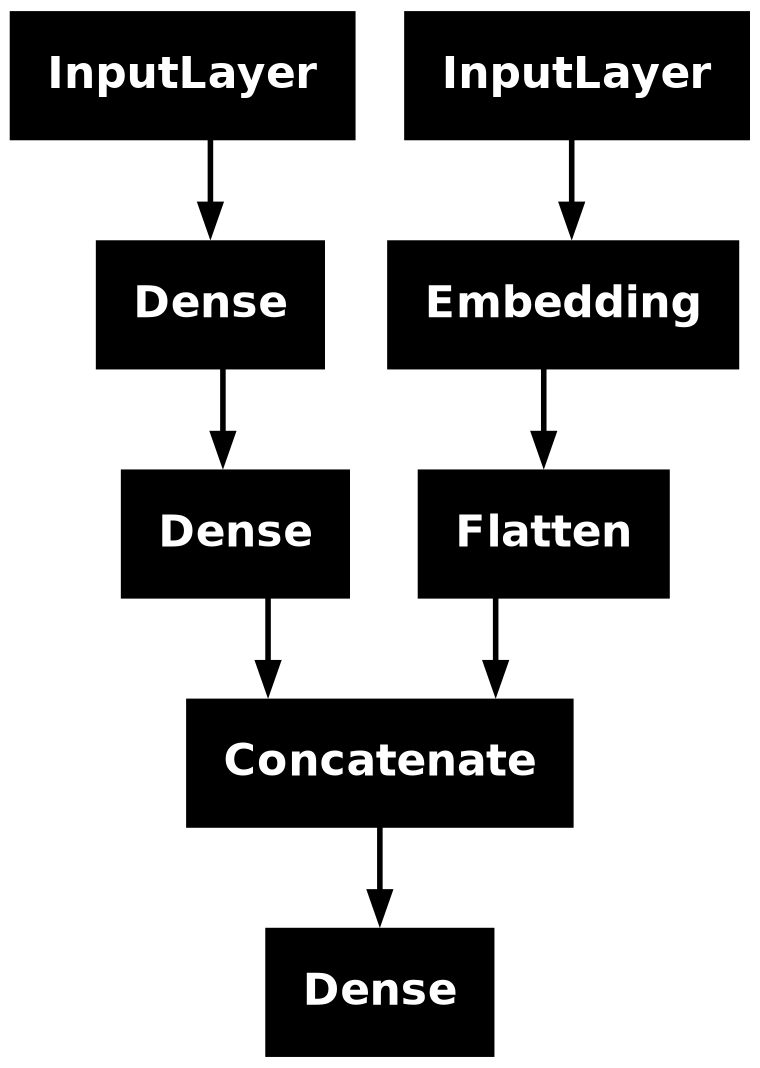

In [48]:
# Inputs
X_inputs = tf.keras.Input(shape=(10, ), name='X_input')
customer_inputs = tf.keras.Input(shape=(1, ), name='customer_input')

# X
X_dense1 = tf.keras.layers.Dense(64, activation='relu', name='X_dense1')(X_inputs)
X_dense2 = tf.keras.layers.Dense(64, activation='relu', name='X_dense2')(X_dense1)

# customers
customer_embedding = tf.keras.layers.Embedding(
    input_dim = 21018,
    output_dim = 64,
    input_length = 1,
    name='customer_embedding'
)(customer_inputs)

customer_flatten = tf.keras.layers.Flatten(name='customer_flatten')(customer_embedding)

# Concatenate
concat = tf.keras.layers.concatenate([X_dense2, customer_flatten], name='concatenate')

# Outputs
outputs = tf.keras.layers.Dense(1, activation='sigmoid', name='output')(concat)

model = tf.keras.Model(inputs=[X_inputs, customer_inputs], outputs=outputs)

print(model.summary())

tf.keras.utils.plot_model(model)

In [50]:
y_train.value_counts()

isFraud
0    34929
1       71
Name: count, dtype: int64

In [51]:
y_test.value_counts()

isFraud
0    14971
1       29
Name: count, dtype: int64

In [49]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

### Training

In [53]:
history = model.fit(
    [X_train, customers_train],
    y_train,
    validation_split=0.2,
    batch_size=32,
    epochs = 10,
    callbacks = [tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True
    )]
)

Epoch 1/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 20s 19ms/step - accuracy: 0.9939 - auc: 0.6465 - loss: 0.0341 - val_accuracy: 0.9977 - val_auc: 0.6992 - val_loss: 0.0151
Epoch 2/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.9980 - auc: 0.8347 - loss: 0.0117 - val_accuracy: 0.9977 - val_auc: 0.9083 - val_loss: 0.0127
Epoch 3/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 20s 18ms/step - accuracy: 0.9980 - auc: 0.9861 - loss: 0.0072 - val_accuracy: 0.9974 - val_auc: 0.7131 - val_loss: 0.0142
Epoch 4/10
875/875 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.9984 - auc: 0.9896 - loss: 0.0043 - val_accuracy: 0.9971 - val_auc: 0.6940 - val_loss: 0.0154


### Results

In [54]:
results = model.evaluate([X_test, customers_test], y_test, verbose=0)

print("Test Accuracy: {:.3f}%".format(results[1]*100))
print("     Test AUC: {:.3f}".format(results[2]))

Test Accuracy: 99.807%
     Test AUC: 0.880


In [55]:
y_true = np.array(y_test)

y_pred = model.predict([X_test, customers_test])

469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


In [60]:
y_pred = (np.squeeze(y_pred) >= 0.5).astype(int)
y_pred

array([0, 0, 0, ..., 0, 0, 0], shape=(15000,))

In [65]:
cm = confusion_matrix(y_true, y_pred)
clr = classification_report(y_true, y_pred, target_names=['Not Fraud', 'Fraud'])

/home/aditya/miniconda3/envs/tfenv/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/aditya/miniconda3/envs/tfenv/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/aditya/miniconda3/envs/tfenv/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1731: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.c

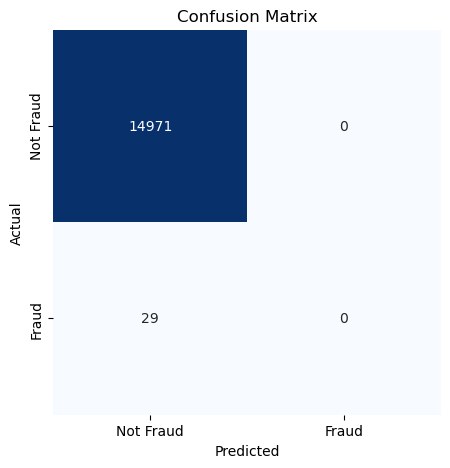

In [63]:
plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, vmin=0, fmt='g', cbar=False, cmap='Blues')
plt.xticks(np.arange(2)+0.5, labels=['Not Fraud', 'Fraud'])
plt.yticks(np.arange(2)+0.5, labels=['Not Fraud', 'Fraud'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

In [66]:
print("Classification Report:\n-------------------------\n", clr)

Classification Report:
-------------------------
               precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00     14971
       Fraud       0.00      0.00      0.00        29

    accuracy                           1.00     15000
   macro avg       0.50      0.50      0.50     15000
weighted avg       1.00      1.00      1.00     15000



#### Handling Class Imbalance

In [90]:
train_df = pd.concat([X_train, pd.Series(np.squeeze(customers_train), name='customer', index=X_train.index), y_train], axis=1)
train_df

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,tp_CASH_IN,tp_CASH_OUT,tp_DEBIT,tp_PAYMENT,tp_TRANSFER,customer,isFraud
17325,-0.476533,-0.331007,-0.333246,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,1.135244,-0.324425,3450,0
13544,-0.473382,-0.325069,-0.327862,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,1.135244,-0.324425,3451,0
49844,0.659963,0.315640,0.469088,2.728245,2.704851,2.147900,-0.618309,-0.115403,-0.880868,-0.324425,579,0
16371,2.643818,-0.258553,-0.333403,2.149973,3.096149,-0.465571,-0.618309,-0.115403,-0.880868,3.082377,146,0
13084,-0.476656,-0.322919,-0.325276,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,1.135244,-0.324425,3452,0
...,...,...,...,...,...,...,...,...,...,...,...,...
7763,-0.282179,-0.332726,-0.333403,-0.312612,-0.378779,-0.465571,1.617313,-0.115403,-0.880868,-0.324425,399,0
15377,-0.193468,-0.332726,-0.333403,-0.250166,-0.231651,-0.465571,1.617313,-0.115403,-0.880868,-0.324425,304,0
17730,-0.045903,-0.330860,-0.268056,-0.131990,-0.134482,2.147900,-0.618309,-0.115403,-0.880868,-0.324425,1149,0
28030,-0.474906,-0.332726,-0.333403,-0.071037,-0.237439,-0.465571,1.617313,-0.115403,-0.880868,-0.324425,685,0


In [91]:
train_df['isFraud'].value_counts()

isFraud
0    34929
1       71
Name: count, dtype: int64

In [92]:
print("Number of examples to sample:", 34929 - 71)

Number of examples to sample: 34858


In [93]:
oversampled_data = train_df.query('isFraud == 1').sample(34858, replace=True, random_state=123)
oversampled_data

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,tp_CASH_IN,tp_CASH_OUT,tp_DEBIT,tp_PAYMENT,tp_TRANSFER,customer,isFraud
1870,-0.408856,-0.321259,-0.333403,-0.343521,-0.388017,-0.465571,1.617313,-0.115403,-0.880868,-0.324425,1428,1
6898,-0.454176,-0.327894,-0.333403,-0.332356,-0.391365,-0.465571,1.617313,-0.115403,-0.880868,-0.324425,2108,1
6583,0.188942,-0.233736,-0.333403,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,-0.880868,3.082377,1378,1
3163,2.522990,0.107987,-0.333403,-0.292894,-0.024354,-0.465571,1.617313,-0.115403,-0.880868,-0.324425,55,1
4104,-0.454256,-0.327906,-0.333403,-0.347251,-0.396106,-0.465571,1.617313,-0.115403,-0.880868,-0.324425,358,1
...,...,...,...,...,...,...,...,...,...,...,...,...
36692,-0.451855,-0.327554,-0.333403,-0.347251,-0.296089,-0.465571,1.617313,-0.115403,-0.880868,-0.324425,3181,1
33473,-0.207165,-0.291730,-0.333403,-0.338556,-0.399715,-0.465571,1.617313,-0.115403,-0.880868,-0.324425,7133,1
12180,-0.486670,-0.332651,-0.333403,-0.345580,-0.399715,-0.465571,1.617313,-0.115403,-0.880868,-0.324425,11307,1
969,3.502961,0.251463,-0.333403,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,-0.880868,3.082377,1920,1


In [94]:
train_df = pd.concat([train_df, oversampled_data], axis=0).sample(frac=1.0, random_state=123).reset_index(drop=True)
train_df

,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,tp_CASH_IN,tp_CASH_OUT,tp_DEBIT,tp_PAYMENT,tp_TRANSFER,customer,isFraud
0,-0.455241,-0.328050,-0.333403,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,-0.880868,3.082377,13802,1
1,-0.433171,1.673388,1.646507,-0.299754,-0.366017,2.147900,-0.618309,-0.115403,-0.880868,-0.324425,1030,0
2,-0.474980,-0.309417,-0.312245,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,1.135244,-0.324425,3572,0
3,-0.388713,-0.332726,-0.333403,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,1.135244,-0.324425,5835,0
4,-0.469634,-0.332726,-0.333403,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,1.135244,-0.324425,4713,0
...,...,...,...,...,...,...,...,...,...,...,...,...
69853,-0.444370,-0.326458,-0.333403,-0.345862,-0.350505,-0.465571,1.617313,-0.115403,-0.880868,-0.324425,2342,1
69854,-0.455568,-0.328098,-0.333403,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,-0.880868,3.082377,8999,1
69855,-0.453397,-0.332726,-0.333403,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,1.135244,-0.324425,12402,0
69856,-0.442919,-0.088634,-0.099816,-0.347251,-0.399715,-0.465571,-0.618309,-0.115403,1.135244,-0.324425,17568,0


In [95]:
train_df['isFraud'].value_counts()

isFraud
1    34929
0    34929
Name: count, dtype: int64

In [100]:
customers_train = train_df['customer'].copy()
y_train = train_df['isFraud'].copy()
X_train = train_df.drop(['isFraud', 'customer'], axis=1).copy()

In [101]:
customers_train

0        13802
1         1030
2         3572
3         5835
4         4713
         ...  
69853     2342
69854     8999
69855    12402
69856    17568
69857    11355
Name: customer, Length: 69858, dtype: int32

In [104]:
# Inputs
X_inputs = tf.keras.Input(shape=(10, ), name='X_input')
customer_inputs = tf.keras.Input(shape=(1, ), name='customer_input')

# X
X_dense1 = tf.keras.layers.Dense(64, activation='relu', name='X_dense1')(X_inputs)
X_dense2 = tf.keras.layers.Dense(64, activation='relu', name='X_dense2')(X_dense1)

# customers
customer_embedding = tf.keras.layers.Embedding(
    input_dim = 21018,
    output_dim = 64,
    input_length = 1,
    name='customer_embedding'
)(customer_inputs)

customer_flatten = tf.keras.layers.Flatten(name='customer_flatten')(customer_embedding)

# Concatenate
concat = tf.keras.layers.concatenate([X_dense2, customer_flatten], name='concatenate')

# Outputs
outputs = tf.keras.layers.Dense(1, activation='sigmoid', name='output')(concat)

model = tf.keras.Model(inputs=[X_inputs, customer_inputs], outputs=outputs)


model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.AUC(name='auc')]
)

/home/aditya/miniconda3/envs/tfenv/lib/python3.10/site-packages/keras/src/layers/core/embedding.py:97: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [105]:
history = model.fit(
    [X_train, customers_train],
    y_train,
    validation_split=0.2,
    batch_size=32,
    epochs = 10,
    callbacks = [tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=2,
        restore_best_weights=True
    )]
)

Epoch 1/10
1747/1747 ━━━━━━━━━━━━━━━━━━━━ 38s 20ms/step - accuracy: 0.9822 - auc: 0.9984 - loss: 0.0568 - val_accuracy: 0.9982 - val_auc: 0.9996 - val_loss: 0.0088
Epoch 2/10
1747/1747 ━━━━━━━━━━━━━━━━━━━━ 33s 19ms/step - accuracy: 0.9984 - auc: 0.9992 - loss: 0.0093 - val_accuracy: 0.9987 - val_auc: 0.9998 - val_loss: 0.0064
Epoch 3/10
1747/1747 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.9986 - auc: 0.9994 - loss: 0.0081 - val_accuracy: 0.9989 - val_auc: 0.9997 - val_loss: 0.0064
Epoch 4/10
1747/1747 ━━━━━━━━━━━━━━━━━━━━ 41s 19ms/step - accuracy: 0.9987 - auc: 0.9994 - loss: 0.0072 - val_accuracy: 0.9988 - val_auc: 0.9997 - val_loss: 0.0057
Epoch 5/10
1747/1747 ━━━━━━━━━━━━━━━━━━━━ 33s 19ms/step - accuracy: 0.9987 - auc: 0.9994 - loss: 0.0070 - val_accuracy: 0.9990 - val_auc: 0.9998 - val_loss: 0.0054
Epoch 6/10
1747/1747 ━━━━━━━━━━━━━━━━━━━━ 33s 19ms/step - accuracy: 0.9989 - auc: 0.9995 - loss: 0.0065 - val_accuracy: 0.9987 - val_auc: 0.9996 - val_loss: 0.0072
Epoch 7/10
1747/

In [106]:
results = model.evaluate([X_test, customers_test], y_test, verbose=0)

print("Test Accuracy: {:.3f}%".format(results[1]*100))
print("     Test AUC: {:.3f}".format(results[2]))

y_true = np.array(y_test)

y_pred = model.predict([X_test, customers_test])
y_pred = (np.squeeze(y_pred) >= 0.5).astype(int)

Test Accuracy: 99.707%
     Test AUC: 0.873
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


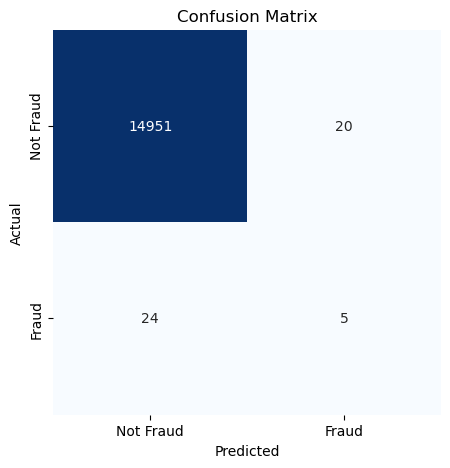

Classification Report:
-------------------------
               precision    recall  f1-score   support

   Not Fraud       1.00      1.00      1.00     14971
       Fraud       0.20      0.17      0.19        29

    accuracy                           1.00     15000
   macro avg       0.60      0.59      0.59     15000
weighted avg       1.00      1.00      1.00     15000



In [108]:
cm = confusion_matrix(y_true, y_pred)
clr = classification_report(y_true, y_pred, target_names=['Not Fraud', 'Fraud'])

plt.figure(figsize=(5, 5))
sns.heatmap(cm, annot=True, vmin=0, fmt='g', cbar=False, cmap='Blues')
plt.xticks(np.arange(2)+0.5, labels=['Not Fraud', 'Fraud'])
plt.yticks(np.arange(2)+0.5, labels=['Not Fraud', 'Fraud'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

print("Classification Report:\n-------------------------\n", clr)